In [5]:
%load_ext autoreload

In [6]:
%autoreload 3

In [7]:
import pandas as pd
from Bio import SeqIO

In [8]:
from roseate import io

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## TOME-like model rerun

Addressing use of term "nearly as accurate" by determinining where models reach parity on amino acid count

```
python scripts/run_tome.py --train-dataset data/validation_datasets/tomes/even_genome_ids.txt --test-dataset data/validation_datasets/tomes/corkrey_genome_ids.txt --traits data/validation_datasets/tomes/genome_topts.tsv --train-proteomes data/validation_datasets/tomes/even_genomes/ --test-proteomes data/validation_datasets/tomes/corkrey_genomes/ --out tests/tome_downsampling/ --threads 24 --reps 100
```

In [124]:
# write temp data with genome uid as index for script
temp_data = pd.read_csv('./../data/high_qual_alignments/temp_data.tsv', sep='\t')
temp_data['genome_id'] = temp_data['seq_id'].apply(lambda x: x.split('|')[1])
temp_data.set_index('genome_id')['temp'].to_csv('./../data/validation_datasets/tomes/genome_topts.tsv', sep='\t')

In [149]:
# data from downsampling script
df = pd.read_csv('./../tests/tome_downsampling/metrics.tsv', sep='\t')

In [150]:
# remove "matched" runs
print(df.shape)
df = df.query("residues != 'full'")
# df = df.query("design == 'full'")
df['residues'] = df['residues'].astype(int) 
df.sort_values('residues', inplace=True)
df

(1401, 5)


,design,residues,rep,r2,rmse
1,full,215,0,-0.007838,18.452435
128,matched,215,63,0.053908,17.878248
129,full,215,64,-0.007838,18.452435
130,matched,215,64,0.001289,18.368696
131,full,215,65,-0.007838,18.452435
...,...,...,...,...,...
1270,matched,1000000,34,0.858279,6.919506
1271,full,1000000,35,0.859990,6.877625
1272,matched,1000000,35,0.858195,6.921567
1262,matched,1000000,30,0.860048,6.876194


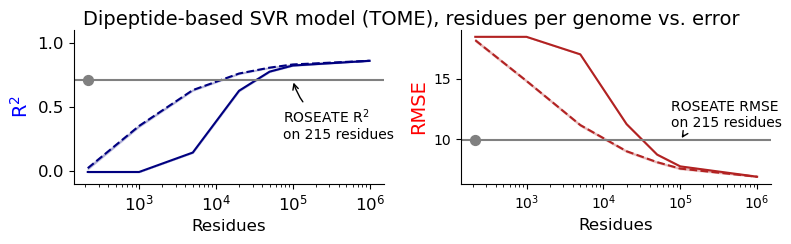

In [153]:

# target_width_px = 2500
# dpi = 400  # 300 DPI is standard for print/publication
# width_in = target_width_px / dpi  # 8.333... inches
# height_in = width_in * (2 / 4)    # 6.25 inches (yields 1875 px height)
# print(width_in, height_in)
fig = plt.figure(figsize=(9, 2))

ax = fig.add_subplot(1,2,1)

sns.lineplot(ax=ax, data=df.query("design == 'full'"), x='residues', y='r2', color='navy', linestyle='-')
sns.lineplot(ax=ax, data=df.query("design == 'matched'"), x='residues', y='r2', color='navy', linestyle='--')
# lgd = ax.legend(labels=['All residues', 'N = X residues'], loc='center left', bbox_to_anchor=(1.2, 0.5), title="Model training")
ax.set_ylabel('R$^{2}$', fontsize=14, color='blue')
ax.set_xlabel('Residues', fontsize=12)
plt.tick_params(top=False, labeltop=False, labelsize=12, axis='both')
ax.set_xscale('log')
ax.set_ylim(-0.1, 1.1)
ax.axhline(0.71, color='gray', linestyle='-')
ax.annotate('ROSEATE R$^{2}$\non 215 residues', (100000, 0.71), (75000, 0.5), va='top', 
            arrowprops=dict(
                arrowstyle="->",
                connectionstyle="arc3,rad=-0.3",  # Negative bends clockwise, positive counter-clockwise
                color="k",
                lw=1
            ))
ax.scatter((215), (0.71), color='gray', s=50, zorder=2)


ax = fig.add_subplot(1,2,2)
sns.lineplot(ax=ax, data=df.query("design == 'full'"), x='residues', y='rmse', color='firebrick', linestyle='-')
sns.lineplot(ax=ax, data=df.query("design == 'matched'"), x='residues', y='rmse', color='firebrick', linestyle='--')# hue='design')
ax.set_ylabel('RMSE', fontsize=14, color='red')
ax.set_xlabel('Residues', fontsize=12)
ax.axhline(9.9, color='gray', linestyle='-')
ax.set_xscale('log')
ax.annotate('ROSEATE RMSE\non 215 residues', (100000, 9.9), (75000, 12), ha='left', va='center',
             arrowprops=dict(
                arrowstyle="->",
                connectionstyle="arc3,rad=0.3",  # Negative bends clockwise, positive counter-clockwise
                color="k",
                lw=1
            ))
ax.scatter((215), (9.9), color='gray', s=50, zorder=2)
sns.despine()
fig.subplots_adjust(wspace=(0.25))
fig.suptitle('Dipeptide-based SVR model (TOME), residues per genome vs. error', fontsize=14)
plt.savefig('./../data/figures/finalized_figures/TOME_retraining.svg')

## Redoing and pipelining input MSA

The canonical number of ADKs with a good structure in this dataset is 8,532. The unaligned sequences for those ADKs are here: `data/20240122_all_adks_filtered.faa` (File A). File A is a subset of File B (`/data/20240122_all_adks.faa`), constructed by concatenating each best-hit adk per genome: `cat adks/*.faa > /data/20240122_all_adks.faa`. Sequences from File B were then folded with ColabFold, and filtered using `notebooks/02_filtering.ipynb` to make File C (`data/metric_tables/20240327_metrics_df_filtered.tsv.gz`).  
  
`File A = File B - File C.`
  
File A is the input to the MSA pipeline.

### Notes on MSA pipeline

Command:
```bash
python scripts/build_backbone.py --sequences data/20240122_all_adks_filtered.faa --exclude data/predictive_models/supporting_data/corkrey_sequence_ids.txt --outgroup data/high_qual_alignments/protein-matching-TIGR01351.fasta --compare-to data/high_qual_alignments/backbone.filtered_only.afa --threads 30 --out runs/backbone_alignment --overwrite --verbose
```

In [157]:
# clean up headers in outgroup file
# records = [r for r in SeqIO.parse('./../data/high_qual_alignments/protein-matching-TIGR01351.fasta', format='fasta')]

## Notes on refitting models
New backbone: data/backbone_alignment

Command:
```
roseate fitting-workflow -o models/even_nb/ -p adk --verbose --threads 10 --alignment data/backbone_alignment/backbone.afa --train-ids reproduce/even_sequence_ids.txt --traits reproduce/per_genome_OGT_data.tsv
```


Layer 1 command:
```
roseate fitting-workflow --alignment data/high_qual_alignments/backbone.filtered_only.afa --train-ids data/predictive_models/supporting_data/even_sequence_ids.txt --traits data/high_qual_alignments/temp_data.tsv --scaler reference/v1_preprint/inputs/predictive_models/supporting_data/ogt_scaler.pickle -o models/layer1 --threads 8 --overwrite --verbose --set embed.contexts=models/v1_preprint/even_full_context.npy --set embed.layer=1
```

Layer 6 command:
```
roseate fitting-workflow --alignment data/high_qual_alignments/backbone.filtered_only.afa --train-ids data/predictive_models/supporting_data/even_sequence_ids.txt --traits data/high_qual_alignments/temp_data.tsv --scaler reference/v1_preprint/inputs/predictive_models/supporting_data/ogt_scaler.pickle -o models/layer6 --threads 8 --overwrite --verbose --set embed.contexts=models/v1_preprint/even_full_context.npy --set embed.layer=6
```

In [163]:
# write corkrey seqs to file
with open('./../data/20240122_all_adks_filtered.faa', 'r') as handle:
    records = [r for r in SeqIO.parse(handle, 'fasta')]
with open('./../reproduce/corkrey_sequence_ids.txt', 'r') as handle:
    corkrey_ids = [i.strip() for i in handle.readlines()]

In [165]:
corkrey_records = [r for r in records if r.id in corkrey_ids]

In [167]:
with open('./../reproduce/corkrey.fasta', 'w') as handle:
    SeqIO.write(corkrey_records, handle, 'fasta')

### Corkrey prediction workflow
```
roseate prediction-workflow --out runs/corkrey_pred_nb --p adk --verbose --save --threads 16 --sequences reproduce/corkrey.fasta --config models/even_nb/model_config.yaml --overwrite
```

In [180]:
from roseate.evaluate import assess_model

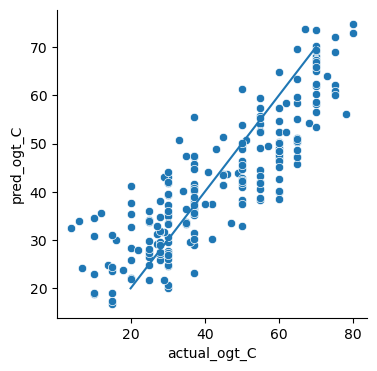

In [182]:
# plot
preds = pd.read_csv('./../runs/corkrey_pred_nb/5_predict/predictions.tsv', sep='\t')

preds['actual_ogt_C'] = preds['protein'].apply(lambda x: float(x.split('|')[3].split('temp=')[-1]))

fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(data=preds, x='actual_ogt_C', y='pred_ogt_C')
plt.plot((20, 70), (20, 70))
sns.despine()

# Consistency measures

### Run context and seed grid

Write commands:
```
python scripts/context_grid.py commands --alignment runs/backbone_alignment/backbone.afa --train-ids reproduce/even_sequence_ids.txt --traits reproduce/per_genome_OGT_data.tsv --sequences data/20240122_all_adks_filtered.faa --test-ids reproduce/corkrey_sequence_ids.txt --main-config models/even_nb/model_config.yaml --runs runs/ --threads 6 > runs/seed_context_grid_commands.10rep.txt
```
grid params for this file:
```
DEPTHS = [0, 2, 4, 8, 16, 32, 64, 128]
SEEDS = 10
SEEDS_AT_MAIN_DEPTH = 10
MAIN_DEPTH = 8
PREDICTION_SEEDS = 10
```

Run commands:
```
# on proteus
parallel -j 5 < runs/seed_context_grid_commands.txt
# on microbe: additional reps
parallel -j 5 < runs/seed_context_grid_commands.10rep.txt
# on proteus, get an early start on large seeds
parallel -j 5 < runs/seed_context_grid_commands.10rep.rev.txt
# test
parallel -j 5 < runs/seed_context_grid_commands.test.txt
```

Run grid on alpine:
After making directories and copying files to inputs
```
# test, from /projects/miho1832/adenylate_kinase_ogt/
bash scripts/alpine_context_grid.sh test
# run
bash scripts/alpine_context_grid.sh submit

```
Summarize:
```
python scripts/context_grid.py summarize --runs runs/ --traits reproduce/per_genome_OGT_data.tsv --results data/context_grid_results/ --top-k 40
```

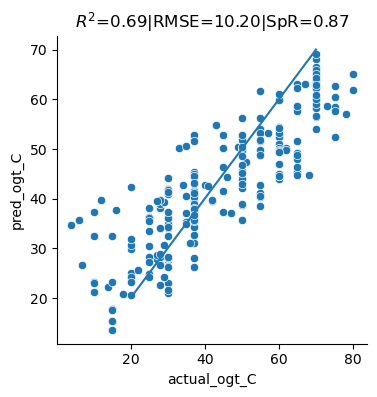

In [187]:
# plot context model
preds = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/runs/grid/d00_s1/predict/5_predict/predictions.tsv', sep='\t')

preds['actual_ogt_C'] = preds['protein'].apply(lambda x: float(x.split('|')[3].split('temp=')[-1]))

fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(data=preds, x='actual_ogt_C', y='pred_ogt_C')
plt.plot((20, 70), (20, 70))
ax.set_title(assess_model(preds['actual_ogt_C'], preds['pred_ogt_C'])[0])
sns.despine()

### Figures of consistency

In [19]:
plotdf = pd.read_csv('./../data/context_grid_results/grid_runs.tsv', sep='\t')
means = plotdf.groupby('depth').agg({'r2':'mean', 'rmse':'mean'}).reset_index()

In [20]:
plotdf.head()

,run,depth,seed,n,r2,rmse,fit_minutes,predict_minutes,peak_memory_gb
0,d00_s1,0,1,230,0.691971,10.201259,NaN,NaN,NaN
1,d00_s2,0,2,230,0.691971,10.201259,NaN,NaN,NaN
2,d00_s3,0,3,230,0.691971,10.201259,NaN,NaN,NaN
3,d02_s1,2,1,230,0.684216,10.328881,NaN,NaN,NaN
4,d02_s2,2,2,230,0.694627,10.157184,NaN,NaN,NaN


In [24]:
means = plotdf.groupby('depth').agg(r2_mean=('r2', 'mean'),
                           r2_std=('r2', 'std'),
                           rmse_mean=('rmse', 'mean'),
                           rmse_std=('rmse', 'std')).reset_index()

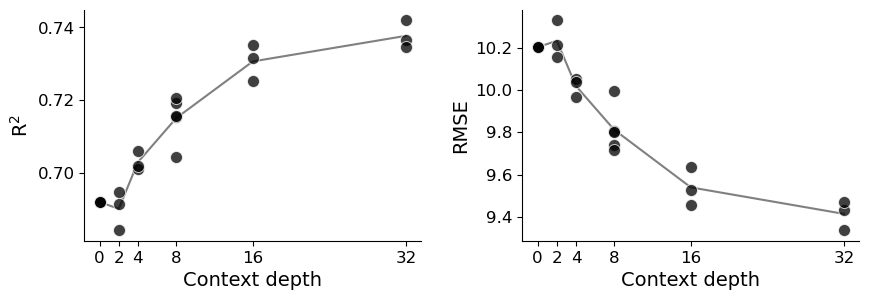

In [64]:
fig = plt.figure(figsize=(10, 3))
ax = fig.add_subplot(1,2,1)
sns.scatterplot(data=plotdf, x='depth', y='r2', s=75, alpha=0.75, color='k', zorder=1)
plt.plot( means['depth'], means['r2_mean'], color='gray', zorder=0)
ax.set_ylabel('R$^{2}$', fontsize=14)
ax.set_xlabel('Context depth', fontsize=14)
ax.set_xticks([0, 2, 4, 8, 16, 32])
plt.tick_params(labelsize=12)
sns.despine()

ax = fig.add_subplot(1,2,2)
sns.scatterplot(data=plotdf, x='depth', y='rmse', s=75, alpha=0.75, color='k', zorder=1)
plt.plot( means['depth'], means['rmse_mean'], color='gray', zorder=0)
ax.set_ylabel('RMSE', fontsize=14)
ax.set_xlabel('Context depth', fontsize=14)
ax.set_xticks([0, 2, 4, 8, 16, 32])
sns.despine()
plt.tick_params(labelsize=12)

fig.subplots_adjust(wspace=0.3)

plt.savefig('./../data/figures/finalized_figures/context_seed_stats.svg', bbox_inches='tight')

In [49]:
# plot of Jaccard and spearman results
component_results = pd.read_csv('./../data/context_grid_results/component_stability.tsv', sep='\t')

In [50]:
fig = plt.figure(figsize=(10, 3))
ax = fig.add_subplot(1,2,1)
sns.scatterplot(data=component_results, x='depth', y='r2', s=75, alpha=0.75)
# plt.plot( means['depth'], means['r2_mean'])
# ax.set_ylabel('R$^{2}$', fontsize=14)
# ax.set_xlabel('Context depth', fontsize=14)
# ax.set_xticks([0, 2, 4, 8, 16, 32])
# plt.tick_params(labelsize=12)
# sns.despine()

# ax = fig.add_subplot(1,2,2)
# sns.scatterplot(data=plotdf, x='depth', y='rmse', s=75, alpha=0.75)
# plt.plot( means['depth'], means['rmse_mean'])
# ax.set_ylabel('RMSE', fontsize=14)
# ax.set_xlabel('Context depth', fontsize=14)
# ax.set_xticks([0, 2, 4, 8, 16, 32])
# sns.despine()
# plt.tick_params(labelsize=12)

# fig.subplots_adjust(wspace=0.3)

# plt.savefig('./../data/figures/finalized_figures/context_seed_stats.svg', bbox_inches='tight')

,site,jaccard,spearman,depth,fits,chance
0,0,1.000000,1.000000,0,3,0.026738
1,1,1.000000,1.000000,0,3,0.026738
2,2,1.000000,1.000000,0,3,0.026738
3,3,1.000000,1.000000,0,3,0.026738
4,4,1.000000,1.000000,0,3,0.026738
...,...,...,...,...,...,...
1279,209,0.270055,0.772504,32,3,0.026738
1280,210,0.284392,0.755495,32,3,0.026738
1281,211,0.257428,0.733138,32,3,0.026738
1282,212,0.238374,0.741232,32,3,0.026738


In [53]:
component_results.groupby(['site', 'depth']).sum()

jaccard  spearman  fits    chance
site depth                                    
0    0      1.000000  1.000000     3  0.026738
     2      0.170787  0.539404     3  0.026738
     4      0.212864  0.662328     3  0.026738
     8      0.223766  0.538177     5  0.026738
     16     0.212670  0.736460     3  0.026738
...              ...       ...   ...       ...
213  2      0.183003  0.669792     3  0.026738
     4      0.193694  0.698988     3  0.026738
     8      0.229195  0.673691     5  0.026738
     16     0.285514  0.742886     3  0.026738
     32     0.224933  0.708321     3  0.026738

[1284 rows x 4 columns]

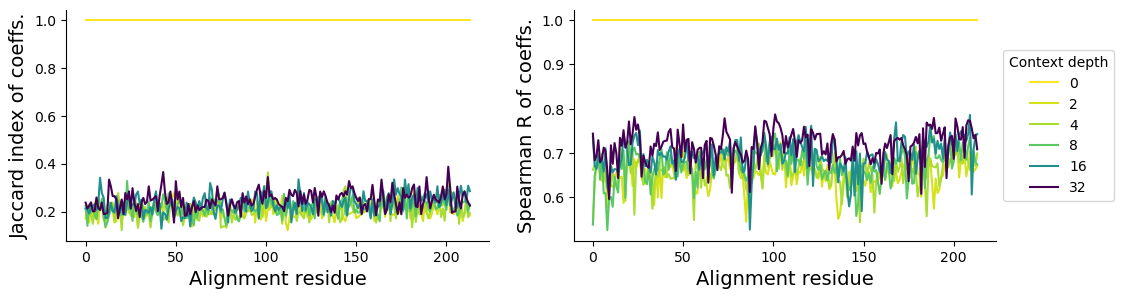

In [75]:
fig = plt.figure(figsize=(12, 3))
ax = fig.add_subplot(1,2,1)
sns.lineplot(data=component_results, x='site', y='jaccard', hue='depth', palette='viridis_r')
ax.set_ylabel('Jaccard index of coeffs.', fontsize=14)
ax.set_xlabel('Alignment residue', fontsize=14)
ax.get_legend().remove()
sns.despine()

ax = fig.add_subplot(1,2,2)
sns.lineplot(data=component_results, x='site', y='spearman', hue='depth', palette='viridis_r')
ax.set_ylabel('Spearman R of coeffs.', fontsize=14)
ax.set_xlabel('Alignment residue', fontsize=14)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='Context depth')
sns.despine()

plt.savefig('./../data/figures/finalized_figures/coefficient_consistency.svg', bbox_inches='tight')